In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import joblib

In [2]:
train_df = pd.read_csv("train_split.csv").fillna("")
test_df = pd.read_csv("test_split.csv").fillna("")

In [3]:
X_train = train_df["title"] + " " + train_df["description"]
X_test = test_df["title"] + " " + test_df["description"]
y_train = train_df["categories"]
y_test = test_df["categories"]

In [4]:
tfv = TfidfVectorizer(stop_words="english", max_features=50000)

In [5]:
X_train_tfv = tfv.fit_transform(X_train)
X_test_tfv = tfv.transform(X_test)

In [6]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfv, y_train);

In [7]:
print(model.score(X_train_tfv, y_train))
print(model.score(X_test_tfv, y_test))

0.9156845238095238
0.8247619047619048


In [8]:
y_pred = model.predict(X_test_tfv)
print(classification_report(y_test, y_pred))

                           precision    recall  f1-score   support

               All Beauty       0.75      0.69      0.72       400
          All Electronics       0.67      0.59      0.63       400
               Appliances       0.95      0.93      0.94       400
    Arts, Crafts & Sewing       0.84      0.85      0.84       400
               Automotive       0.87      0.85      0.86       400
                     Baby       0.76      0.83      0.79       400
            Baby Products       0.83      0.63      0.72       400
                   Beauty       0.75      0.73      0.74       400
Cell Phones & Accessories       0.86      0.91      0.89       400
Clothing, Shoes & Jewelry       0.77      0.83      0.80       400
              Electronics       0.84      0.85      0.84       400
   Grocery & Gourmet Food       0.92      0.96      0.94       400
   Health & Personal Care       0.72      0.74      0.73       400
  Industrial & Scientific       0.73      0.79      0.76     

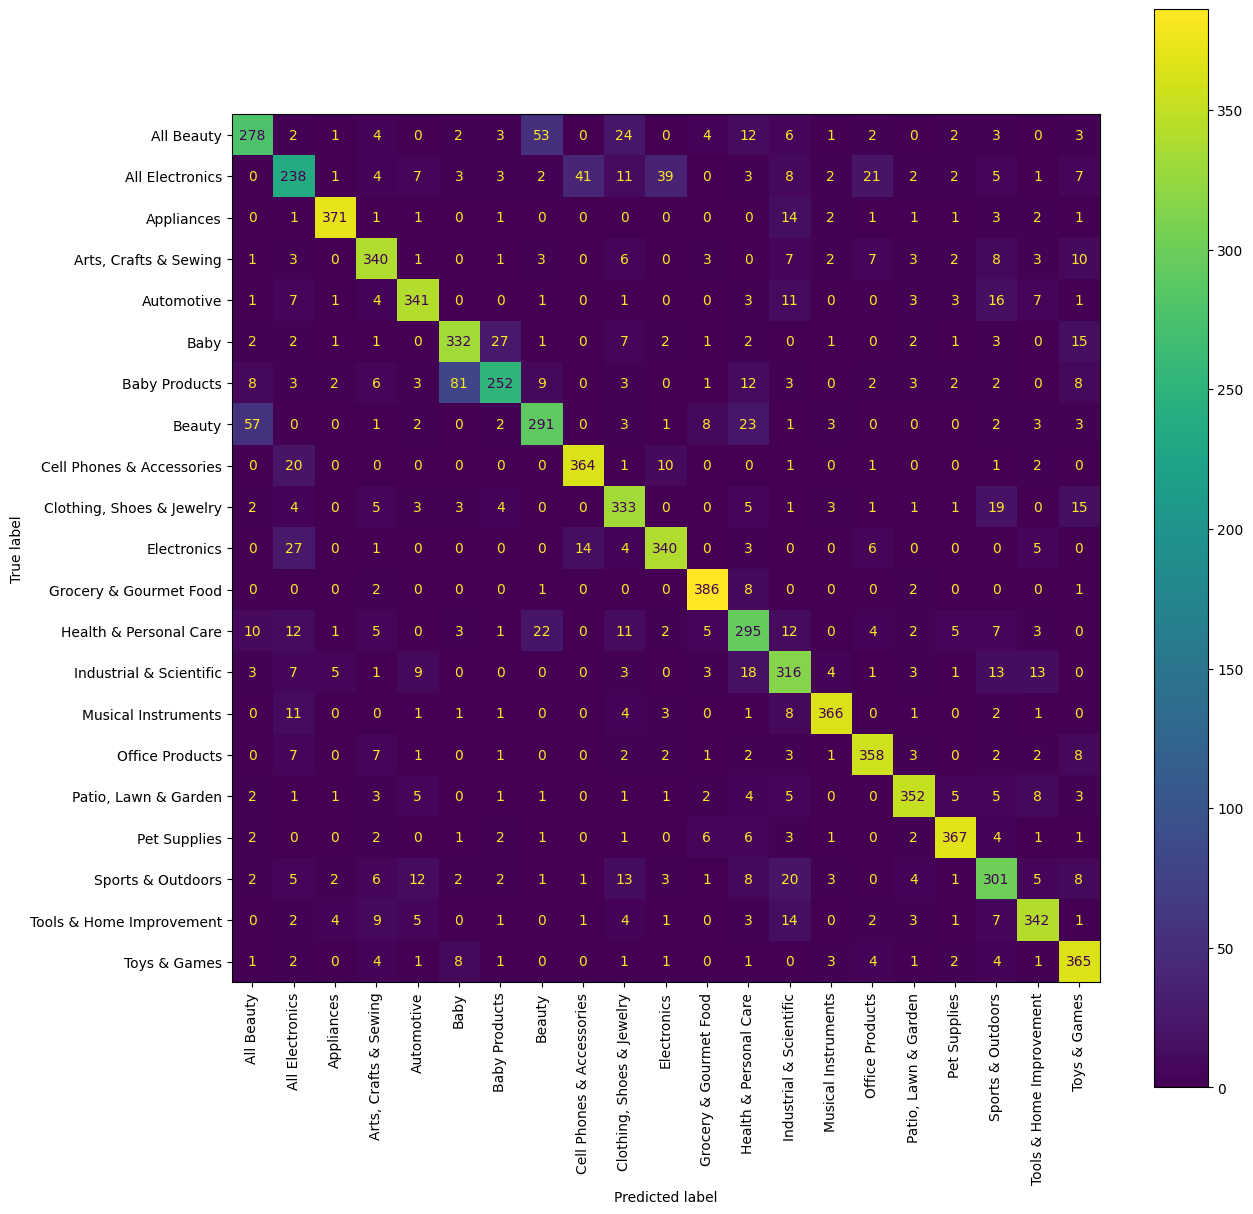

In [9]:
fig, ax = plt.subplots(figsize=(14,14))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation="vertical")
plt.show()

In [10]:
joblib.dump(tfv, "tfidf.pkl")
joblib.dump(model, "text_model.pkl")

['text_model.pkl']